# Pima diabetes: four-criterion QUBO + D-Wave + Random Forest

**Practice goal:** select exactly **4 of 8 original features**, then train a Random Forest.

**Training data → relevance, redundancy, interaction, cost → QUBO → Advantage2 QPU → four columns → Random Forest**

This executed notebook includes a real hardware result. Identical reruns load that job's saved response and retain its original timings. Set `FRESH_QPU = True` to request a new job.

The supplied paper, *Quantum Annealing based Feature Selection in Machine Learning* (Pranjić et al.), uses MI/conditional MI and the Kerberos hybrid sampler (pages 2–4). This notebook implements your requested **correlation-based extension**, with an explicit pair-product interaction proxy and feature cost. It is a practice surrogate, not an exact reproduction of that paper or Hall's ratio-based CFS.

## 1. Fixed settings

Use the repository's `.venv` kernel. Dependencies are in this folder's `requirements.txt`.
The reusable functions are in `pima_four_criteria.py`. No API token is printed or saved.

Weights and example costs are fixed before looking at test performance. There is no parameter search.

In [1]:
from pathlib import Path
import sys
import tempfile
import os
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "pima-four-criteria-mpl"))

for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    candidates = [parent, parent / "Quantum annealing for feature selection"]
    found = next((p for p in candidates if (p / "pima_four_criteria.py").is_file()), None)
    if found is not None:
        PROJECT = found
        break
else:
    raise FileNotFoundError("Launch from the repository or this notebook's folder.")
sys.path.insert(0, str(PROJECT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import dimod
import pima_four_criteria as practice

FEATURES = practice.FEATURES
K = practice.K
FRESH_QPU = False
OUTPUT = PROJECT / "outputs/four_criteria"
assert K == 4
print("k =", K, "| reads =", practice.NUM_READS, "| seed =", practice.SEED)
display(pd.Series(practice.WEIGHTS, name="Fixed weight").to_frame())

Matplotlib is building the font cache; this may take a moment.


k = 4 | reads = 1000 | seed = 42


,Fixed weight
relevance,1.00
redundancy,0.50
interaction,0.50
cost,0.25


## 2. Dataset and split

Pima contains 768 records, eight predictors, and binary `Outcome`. Keep all rows and verify the existing raw CSV checksum. Convert zero Glucose, BloodPressure, SkinThickness, Insulin, and BMI to missing values; zero pregnancies remains valid. Use the same stratified 80/20 split for every model.

Imputation and all selection statistics use **training rows only**. The test set is used only for the final classifier comparison. This is one previously explored benchmark split, not an independent clinical evaluation.

In [2]:
raw, X_train, X_test, y_train, y_test = practice.load_data()
print("Raw shape:", raw.shape, "| duplicate rows:", raw.duplicated().sum())
print("Training:", len(X_train), "| test:", len(X_test))
print("Class counts:", raw.Outcome.value_counts().sort_index().to_dict())
display(pd.DataFrame({
    "zero_values_in_raw": raw[FEATURES].eq(0).sum(),
    "training_missing_after_policy": X_train.isna().sum(),
    "test_missing_after_policy": X_test.isna().sum(),
}))

Raw shape: (768, 9) | duplicate rows: 0
Training: 614 | test: 154
Class counts: {0: 500, 1: 268}


,zero_values_in_raw,training_missing_after_policy,test_missing_after_policy
Pregnancies,111,0,0
Glucose,5,4,1
BloodPressure,35,23,12
SkinThickness,227,175,52
Insulin,374,290,84
BMI,11,9,2
DiabetesPedigreeFunction,0,0,0
Age,0,0,0


## 3. Calculate all four criteria

For training-standardized columns $z_i=(X_i-\bar X_i)/\sigma_i$:

| Criterion | Score | Goal |
|---|---|---|
| Relevance | $r_i=|\mathrm{corr}(X_i,y)|$ | Higher |
| Redundancy | $R_{ij}=|\mathrm{corr}(X_i,X_j)|$ | Lower |
| Interaction | $S_{ij}=|\mathrm{corr}(z_i z_j,y)|$ | Higher |
| Feature cost | $c_i=\mathrm{cost}_i/\max_j\mathrm{cost}_j$ | Lower |

The pair-product score is a simple statistical interaction **proxy**, not conditional mutual information or pure synergy. It may overlap with main effects and misses some nonlinear patterns. Both pair matrices have zero diagonals.

**Pima supplies no feature costs.** The values below are editable, illustrative acquisition-effort units, not measured healthcare prices. With fixed $k$, equal costs would give every eligible subset the same cost term.

,feature,relevance,example_cost_units,normalized_cost,training_median
0,Pregnancies,0.2082,1.0,0.2,3.0000
1,Glucose,0.5123,4.0,0.8,117.0000
2,BloodPressure,0.1834,1.0,0.2,72.0000
3,SkinThickness,0.2343,2.0,0.4,29.0000
4,Insulin,0.2459,5.0,1.0,125.0000
5,BMI,0.3288,1.0,0.2,32.4000
6,DiabetesPedigreeFunction,0.1653,2.0,0.4,0.3825
7,Age,0.2407,1.0,0.2,29.0000


Missing values after training-fitted imputation: 0


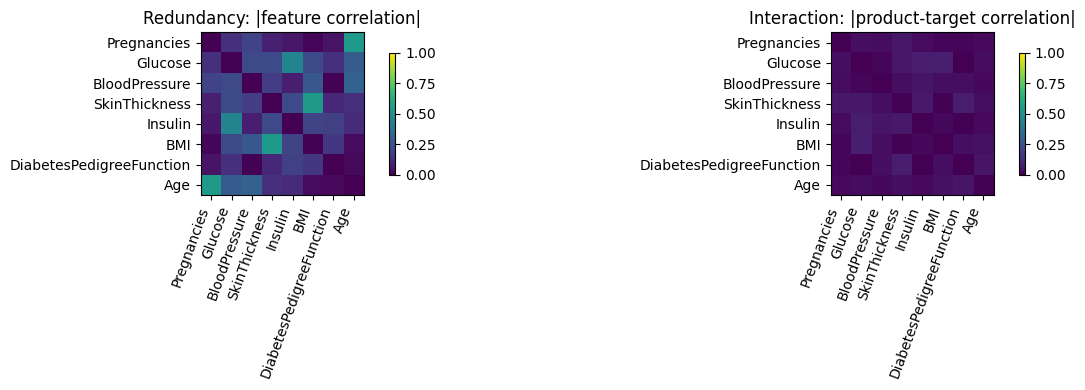

In [3]:
scores = practice.compute_scores(X_train, y_train)
criteria = pd.DataFrame({
    "feature": FEATURES,
    "relevance": scores["relevance"],
    "example_cost_units": scores["raw_cost"],
    "normalized_cost": scores["cost"],
    "training_median": scores["medians"],
})
display(criteria.round(4))
print("Missing values after training-fitted imputation: 0")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, key, title in zip(axes, ["redundancy", "interaction"],
                          ["Redundancy: |feature correlation|", "Interaction: |product-target correlation|"]):
    im = ax.imshow(scores[key], cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(8), FEATURES, rotation=70, ha="right")
    ax.set_yticks(range(8), FEATURES)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.75)
fig.tight_layout()
plt.show()

## 4. Build the QUBO for exactly four features

Let $x_i=1$ mean select original feature $i$, and $C=\binom{4}{2}=6$.
Minimize

$$E(x)=-\frac{\alpha}{4}\sum_i r_i x_i
+\frac{\beta}{6}\sum_{i<j}R_{ij}x_ix_j
-\frac{\gamma}{6}\sum_{i<j}S_{ij}x_ix_j
+\frac{\delta}{4}\sum_i c_i x_i
+A\left(\sum_i x_i-4\right)^2.$$

Use $(\alpha,\beta,\gamma,\delta)=(1,0.5,0.5,0.25)$. Normalize sums by their number of selected terms so one feature criterion and one pair criterion have comparable scales.

The upper triangular entries are

$$Q_{ii}=\frac{-\alpha r_i+\delta c_i}{4}+A(1-8),\quad
Q_{ij}=\frac{\beta R_{ij}-\gamma S_{ij}}6+2A\quad(i<j),$$

with constant offset $16A$. Count each pair once. The offset is retained in the BQM.

If the unpenalized coefficients are $a_i,b_{ij}$, choose
$A>\max_i(|a_i|+\sum_{j\ne i}|b_{ij}|)$.
One flip toward size four reduces the penalty by at least $A$, exceeding any possible increase in the base objective. Thus every ideal global minimum has four features. Hardware samples can still be noisy.

In [4]:
bqm, Q, penalty = practice.build_qubo(scores)
Q_table = pd.DataFrame(0.0, index=FEATURES, columns=FEATURES)
for (i, j), value in Q.items():
    Q_table.iloc[i, j] = value
print(f"Penalty A = {penalty:.6f} | constant offset = {bqm.offset:.6f}")
display(Q_table.round(4))

Penalty A = 0.292701 | constant offset = 4.683210


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Pregnancies,-2.0884,0.594,0.5995,0.5873,0.5884,0.5851,0.5885,0.6280
Glucose,0.0000,-2.127,0.6024,0.5987,0.6165,0.5972,0.5969,0.6067
BloodPressure,0.0000,0.000,-2.0822,0.5974,0.5879,0.6048,0.5828,0.6099
SkinThickness,0.0000,0.000,0.0000,-2.0825,0.5983,0.6297,0.5878,0.5936
Insulin,0.0000,0.000,0.0000,0.0000,-2.0479,0.6008,0.6013,0.5935
BMI,0.0000,0.000,0.0000,0.0000,0.0000,-2.1186,0.5960,0.5840
DiabetesPedigreeFunction,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,-2.0652,0.5829
Age,0.0000,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,-2.0966


## 5. Verify every assignment and obtain the exact CPU reference

Only eight binary variables means 256 possible assignments, including 70 size-four subsets. Exhaustively check the expanded QUBO against the original formula and verify every global minimum has size four. This makes solution quality directly checkable; it does not claim a quantum speed advantage.

In [5]:
exact_minimum = practice.verify_qubo(bqm, scores, penalty)
exact_samples = dimod.ExactSolver().sample(bqm)
exact_bits = practice.best_feasible(exact_samples)
print("PASS: all 256 energies match; every ground state selects exactly four features.")
print("Exact minimum:", exact_minimum)
print("Exact subset:", [FEATURES[i] for i in np.flatnonzero(exact_bits)])

PASS: all 256 energies match; every ground state selects exactly four features.
Exact minimum: -0.16043330358395874
Exact subset: ['Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age']


## 6. Run on a direct Advantage2 QPU

`solve_qpu` uses `EmbeddingComposite(DWaveSampler(...))`, reads `DWAVE_API_TOKEN` privately from the environment or repository `.env`, discovers an online production Advantage2 solver, and requests 1,000 reads at 20 microseconds annealing per read. It records the actual solver name, working graph, and job ID.

The quantum step selects features; Random Forest runs on the CPU. Only the eight-variable QUBO is sent to D-Wave. The software resolves the returned sample set before stopping the wall clock.

A saved identical response is reused on ordinary reruns. An incomplete submission marker blocks automatic duplicate submissions. Hardware failure is explicit; a CPU result is never substituted for a QPU result.

In [6]:
qpu_samples, qpu_metadata = practice.solve_qpu(bqm, OUTPUT, fresh=FRESH_QPU)
qpu_bits = practice.best_feasible(qpu_samples)
print("Solver:", qpu_metadata["solver_identity"])
print("Job ID:", qpu_metadata["problem_id"])
print("Response source:", "saved real hardware job" if qpu_metadata["cached"] else "new real hardware job")
print("Physical qubits:", qpu_metadata["physical_qubits_used"],
      "| maximum chain length:", qpu_metadata["max_chain_length"])
if qpu_bits is None:
    print("No size-four subset returned; hardware selection is unavailable.")
else:
    assert qpu_bits.sum() == K
    print("QPU subset:", [FEATURES[i] for i in np.flatnonzero(qpu_bits)])
    energy = bqm.energy(dict(enumerate(qpu_bits)))
    print("Gap from exact optimum:", energy - exact_minimum)
    display(pd.Series(practice.energy_terms(qpu_bits, scores, penalty), name="Energy contribution").to_frame())

qpu_frame = pd.DataFrame([
    {"energy": row.energy, "num_features": sum(row.sample.values()),
     "occurrences": row.num_occurrences} for row in qpu_samples.data()
])
returned_reads = int(qpu_frame.occurrences.sum())
print("Returned reads:", returned_reads)
print("Valid-size read fraction:", qpu_frame.loc[qpu_frame.num_features.eq(K), "occurrences"].sum() / returned_reads)
optimal = np.isclose(qpu_frame.energy, exact_minimum, atol=1e-8, rtol=0)
print("Optimal read fraction:", qpu_frame.loc[optimal, "occurrences"].sum() / returned_reads)

Solver: {'name': 'Advantage2_system1', 'version': {'graph_id': '01b03fc8dc'}}
Job ID: 92c959db-320e-4a5e-ac6a-af6010b07c0a
Response source: saved real hardware job
Physical qubits: 13 | maximum chain length: 2
QPU subset: ['Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Gap from exact optimum: 2.7755575615628914e-16


,Energy contribution
relevance,-0.311763
redundancy,0.072634
interaction,-0.021304
cost,0.100000
cardinality_penalty,0.000000


Returned reads: 1000
Valid-size read fraction: 1.0
Optimal read fraction: 0.048


## 7. Train Random Forest on the selected original features

All methods use the same Random Forest: 300 trees, `min_samples_leaf=2`, seed 42, and a fixed 0.5 probability threshold. Each fits median imputation only on its selected training columns. Random Forest does not need scaling; standardized columns above were used only to calculate interaction scores.

Choose the QPU subset by feasible **QUBO energy**, never by test accuracy. Compare all eight columns, top-four individual correlations, the exact-QUBO subset, and the returned QPU subset. The original test labels are untouched until this step.

In [7]:
top_bits = np.zeros(8, dtype=int)
top_bits[np.argsort(-scores["relevance"], kind="stable")[:K]] = 1
subsets = {"All features": np.ones(8, dtype=int), "Top-4 relevance": top_bits,
           "Exact QUBO (CPU)": exact_bits}
if qpu_bits is not None:
    subsets["D-Wave QPU"] = qpu_bits
comparison = pd.DataFrame([
    {"method": name, **practice.evaluate_subset(bits, X_train, X_test, y_train, y_test)}
    for name, bits in subsets.items()
])
display(comparison[["method", "num_features", "example_cost_units", "accuracy", "balanced_accuracy",
                    "precision", "recall", "f1", "roc_auc"]].round(4))
display(comparison[["method", "selected_features", "confusion_matrix"]])
print("Confusion matrix order: [[TN, FP], [FN, TP]].")

,method,num_features,example_cost_units,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,All features,8,17,0.7468,0.7028,0.6667,0.5556,0.6061,0.8131
1,Top-4 relevance,4,11,0.7403,0.7020,0.6458,0.5741,0.6078,0.8100
2,Exact QUBO (CPU),4,8,0.7532,0.7163,0.6667,0.5926,0.6275,0.8067
3,D-Wave QPU,4,8,0.7532,0.7163,0.6667,0.5926,0.6275,0.8067


,method,selected_features,confusion_matrix
0,All features,"Pregnancies, Glucose, BloodPressure, SkinThick...","[[85, 15], [24, 30]]"
1,Top-4 relevance,"Glucose, Insulin, BMI, Age","[[83, 17], [23, 31]]"
2,Exact QUBO (CPU),"Glucose, BMI, DiabetesPedigreeFunction, Age","[[84, 16], [22, 32]]"
3,D-Wave QPU,"Glucose, BMI, DiabetesPedigreeFunction, Age","[[84, 16], [22, 32]]"


Confusion matrix order: [[TN, FP], [FN, TP]].


## 8. QPU time and overhead

QPU access includes programming and sampling; it is larger than annealing alone. D-Wave's raw API timing fields are in **microseconds**.

**Total overhead = original total solver wall time − QPU access time.** It includes solver setup, embedding, network transfer, queue waits, result decoding, and device-side access overhead. This difference cannot isolate those components individually. The total solver wall interval ends after resolving samples, before client teardown; data preparation, exact verification, and Random Forest execution are outside it.

The separate API field `qpu_access_overhead_time` is a device initialization measurement. It is already included in the wall-time residual, so do not add it again. For cached responses, all solver timings below belong to the **original hardware submission**, not the cache read.

,Measurement,Seconds
0,QPU access (programming + sampling),0.163232
1,QPU sampling (anneal + readout + delay),0.128600
2,"Annealing only, all reads",0.020000
3,Device access overhead (API field),0.000574
4,Solver setup,0.137393
5,Sample call through resolved result,2.581309
6,Sample-call overhead,2.418077
7,Total solver wall time,2.719109
8,Total overhead (wall minus QPU access),2.555877


,D-Wave field,microseconds,seconds
0,qpu_sampling_time,128600.00,0.128600
1,qpu_anneal_time_per_sample,20.00,0.000020
2,qpu_readout_time_per_sample,48.03,0.000048
3,qpu_access_time,163231.60,0.163232
4,qpu_access_overhead_time,574.40,0.000574
5,qpu_programming_time,34631.60,0.034632
6,qpu_delay_time_per_sample,60.57,0.000061
7,post_processing_overhead_time,50.00,0.000050
8,total_post_processing_time,50.00,0.000050


,method,fit_s,predict_s
0,All features,0.243767,0.011933
1,Top-4 relevance,0.188167,0.011634
2,Exact QUBO (CPU),0.190925,0.011492
3,D-Wave QPU,0.191651,0.011494


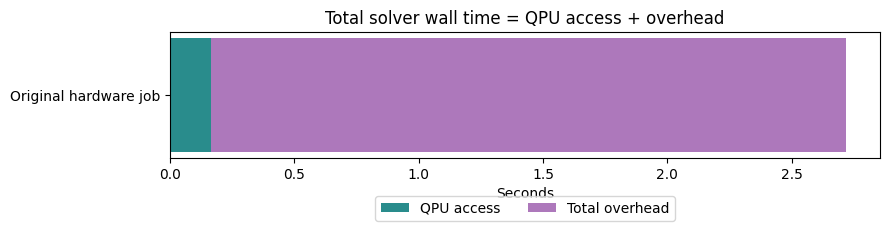

In [8]:
timing_us = qpu_metadata["timing_us"]
raw_timing = pd.DataFrame([
    {"D-Wave field": key, "microseconds": value, "seconds": value / 1e6}
    for key, value in timing_us.items()
])
anneal_only_s = timing_us["qpu_anneal_time_per_sample"] * returned_reads / 1e6
runtime = pd.DataFrame([
    {"Measurement": "QPU access (programming + sampling)", "Seconds": qpu_metadata["qpu_access_s"]},
    {"Measurement": "QPU sampling (anneal + readout + delay)", "Seconds": timing_us["qpu_sampling_time"] / 1e6},
    {"Measurement": "Annealing only, all reads", "Seconds": anneal_only_s},
    {"Measurement": "Device access overhead (API field)", "Seconds": timing_us.get("qpu_access_overhead_time", np.nan) / 1e6},
    {"Measurement": "Solver setup", "Seconds": qpu_metadata["setup_wall_s"]},
    {"Measurement": "Sample call through resolved result", "Seconds": qpu_metadata["sample_call_wall_s"]},
    {"Measurement": "Sample-call overhead", "Seconds": qpu_metadata["sample_call_overhead_s"]},
    {"Measurement": "Total solver wall time", "Seconds": qpu_metadata["total_solver_wall_s"]},
    {"Measurement": "Total overhead (wall minus QPU access)", "Seconds": qpu_metadata["total_overhead_s"]},
])
display(runtime.round(6))
display(raw_timing)
display(comparison[["method", "fit_s", "predict_s"]].round(6))
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.barh(["Original hardware job"], [qpu_metadata["qpu_access_s"]], label="QPU access", color="#298c8c")
ax.barh(["Original hardware job"], [qpu_metadata["total_overhead_s"]],
        left=[qpu_metadata["qpu_access_s"]], label="Total overhead", color="#ad78bb")
ax.set_xlabel("Seconds")
ax.set_title("Total solver wall time = QPU access + overhead")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
fig.tight_layout()
plt.show()

## 9. Explain the result

The score weights, interaction definition, and example costs determine what the QUBO considers a good subset. Matching its exact optimum verifies the optimization objective; classifier performance is a separate question. One small hardware job does not establish a quantum speed advantage.

In [9]:
if qpu_bits is not None:
    row = comparison.loc[comparison.method.eq("D-Wave QPU")].iloc[0]
    baseline = comparison.loc[comparison.method.eq("All features")].iloc[0]
    matches = np.isclose(bqm.energy(dict(enumerate(qpu_bits))), exact_minimum, atol=1e-8, rtol=0)
    display(Markdown(
        f"The real **{qpu_metadata['solver_identity']['name']}** job selected exactly **4 features**: "
        f"**{row.selected_features}**. It {'matched' if matches else 'did not match'} the exact QUBO optimum. "
        f"Random Forest achieved **{row.accuracy:.2%} accuracy**, **F1 {row.f1:.4f}**, and "
        f"**ROC AUC {row.roc_auc:.4f}** on 154 test records. The all-eight-feature baseline had "
        f"**{baseline.accuracy:.2%} accuracy**. Original QPU access time was "
        f"**{qpu_metadata['qpu_access_s']:.6f} s**, total overhead **{qpu_metadata['total_overhead_s']:.6f} s**, "
        f"and total solver wall time **{qpu_metadata['total_solver_wall_s']:.6f} s**. "
        "Costs were illustrative practice assumptions."
    ))
else:
    print("Hardware returned no feasible subset, so no QPU classifier result is reported.")

The real **Advantage2_system1** job selected exactly **4 features**: **Glucose, BMI, DiabetesPedigreeFunction, Age**. It matched the exact QUBO optimum. Random Forest achieved **75.32% accuracy**, **F1 0.6275**, and **ROC AUC 0.8067** on 154 test records. The all-eight-feature baseline had **74.68% accuracy**. Original QPU access time was **0.163232 s**, total overhead **2.555877 s**, and total solver wall time **2.719109 s**. Costs were illustrative practice assumptions.

## References and rerunning

- [Supplied paper's online text](https://arxiv.org/html/2411.19609v1), equations 7 and 11.
- [D-Wave: solver selection and graph identity](https://docs.dwavequantum.com/en/latest/quantum_research/quantum_solvers_intro.html).
- [D-Wave: operation and timing](https://docs.dwavequantum.com/en/latest/quantum_research/operation_timing.html).
- [Pima dataset mirror notes](https://github.com/jbrownlee/Datasets/blob/master/pima-indians-diabetes.names).
- [Random Forest API](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

See **FOUR-CRITERIA-README.md** for the derivation and command-line options.
Edit `FEATURE_COSTS` or `WEIGHTS` in `pima_four_criteria.py` before restarting the kernel.
Changing the BQM creates a different job fingerprint, so the next hardware run submits a new problem.
The command-line implementation writes the full results to `outputs/four_criteria/results.json`.